# 1. Chargement des données

Lien du dataset : https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment/data

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud, STOPWORDS

import nltk

nltk.download("stopwords")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\anasa\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

# 2. Analyse exploratoire (EDA)

In [2]:
dataset = pd.read_csv("dataset.csv")

In [3]:
dataset.head()

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


In [4]:
# (nombre de lignes, nombre de colonnes)
dataset.shape

(14640, 15)

In [5]:
# les colonnes dans le dataset
dataset.columns

Index(['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence',
       'negativereason', 'negativereason_confidence', 'airline',
       'airline_sentiment_gold', 'name', 'negativereason_gold',
       'retweet_count', 'text', 'tweet_coord', 'tweet_created',
       'tweet_location', 'user_timezone'],
      dtype='object')

In [6]:
# des informations sur le jeu de données
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   tweet_id                      14640 non-null  int64  
 1   airline_sentiment             14640 non-null  object 
 2   airline_sentiment_confidence  14640 non-null  float64
 3   negativereason                9178 non-null   object 
 4   negativereason_confidence     10522 non-null  float64
 5   airline                       14640 non-null  object 
 6   airline_sentiment_gold        40 non-null     object 
 7   name                          14640 non-null  object 
 8   negativereason_gold           32 non-null     object 
 9   retweet_count                 14640 non-null  int64  
 10  text                          14640 non-null  object 
 11  tweet_coord                   1019 non-null   object 
 12  tweet_created                 14640 non-null  object 
 13  t

In [7]:
# lister les valeurs catégorielles
dataset.select_dtypes(include="object").columns

Index(['airline_sentiment', 'negativereason', 'airline',
       'airline_sentiment_gold', 'name', 'negativereason_gold', 'text',
       'tweet_coord', 'tweet_created', 'tweet_location', 'user_timezone'],
      dtype='object')

In [8]:
# la taille des valeurs catégorielles
len(dataset.select_dtypes(include="object").columns)

11

In [9]:
# lister les valeurs numeriques
dataset.select_dtypes(include="number").columns

Index(['tweet_id', 'airline_sentiment_confidence', 'negativereason_confidence',
       'retweet_count'],
      dtype='object')

In [10]:
# la taille des valeurs numériques
len(dataset.select_dtypes(include="number").columns)

4

In [11]:
# les statistiques
dataset.describe(include="all")

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
count,1.464000e+04,14640,14640.000000,9178,10522.000000,14640,40,14640,32,14640.000000,14640,1019,14640,9907,9820
unique,NaN,3,NaN,10,NaN,6,3,7701,13,NaN,14427,832,14247,3081,85
top,NaN,negative,NaN,Customer Service Issue,NaN,United,negative,JetBlueNews,Customer Service Issue,NaN,@united thanks,"[0.0, 0.0]",2015-02-24 09:54:34 -0800,"Boston, MA",Eastern Time (US & Canada)
freq,NaN,9178,NaN,2910,NaN,3822,32,63,12,NaN,6,164,5,157,3744
mean,5.692184e+17,NaN,0.900169,NaN,0.638298,NaN,NaN,NaN,NaN,0.082650,NaN,NaN,NaN,NaN,NaN
std,7.791112e+14,NaN,0.162830,NaN,0.330440,NaN,NaN,NaN,NaN,0.745778,NaN,NaN,NaN,NaN,NaN
min,5.675883e+17,NaN,0.335000,NaN,0.000000,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN
25%,5.685592e+17,NaN,0.692300,NaN,0.360600,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN
50%,5.694779e+17,NaN,1.000000,NaN,0.670600,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN
75%,5.698905e+17,NaN,1.000000,NaN,1.000000,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN


# 3. Valeurs manquantes

In [12]:
dataset.isnull().values.any()

True

In [13]:
dataset.isnull().values.sum()

61962

In [14]:
dataset.isna().sum()

tweet_id                            0
airline_sentiment                   0
airline_sentiment_confidence        0
negativereason                   5462
negativereason_confidence        4118
airline                             0
airline_sentiment_gold          14600
name                                0
negativereason_gold             14608
retweet_count                       0
text                                0
tweet_coord                     13621
tweet_created                       0
tweet_location                   4733
user_timezone                    4820
dtype: int64

In [15]:
dataset["retweet_count"].value_counts()

retweet_count
0     13873
1       640
2        66
3        22
4        17
5         5
7         3
6         3
22        2
8         1
32        1
28        1
9         1
18        1
11        1
31        1
15        1
44        1
Name: count, dtype: int64

In [16]:
dataset["negativereason"].value_counts()

negativereason
Customer Service Issue         2910
Late Flight                    1665
Can't Tell                     1190
Cancelled Flight                847
Lost Luggage                    724
Bad Flight                      580
Flight Booking Problems         529
Flight Attendant Complaints     481
longlines                       178
Damaged Luggage                  74
Name: count, dtype: int64

In [17]:
dataset["user_timezone"].value_counts()

user_timezone
Eastern Time (US & Canada)    3744
Central Time (US & Canada)    1931
Pacific Time (US & Canada)    1208
Quito                          738
Atlantic Time (Canada)         497
                              ... 
Warsaw                           1
Bucharest                        1
Wellington                       1
Sarajevo                         1
Saskatchewan                     1
Name: count, Length: 85, dtype: int64

In [18]:
dataset["tweet_location"].value_counts()

tweet_location
Boston, MA              157
New York, NY            156
Washington, DC          150
New York                127
USA                     126
                       ... 
Seattle (duh!)            1
South ~O-H-I-O~ Side      1
Pocono Raceway            1
denver, co                1
Nigeria,lagos             1
Name: count, Length: 3081, dtype: int64

In [19]:
dataset["tweet_created"]

0        2015-02-24 11:35:52 -0800
1        2015-02-24 11:15:59 -0800
2        2015-02-24 11:15:48 -0800
3        2015-02-24 11:15:36 -0800
4        2015-02-24 11:14:45 -0800
                   ...            
14635    2015-02-22 12:01:01 -0800
14636    2015-02-22 11:59:46 -0800
14637    2015-02-22 11:59:15 -0800
14638    2015-02-22 11:59:02 -0800
14639    2015-02-22 11:58:51 -0800
Name: tweet_created, Length: 14640, dtype: object

In [20]:
dataset["name"].value_counts()

name
JetBlueNews       63
kbosspotter       32
_mhertz           29
otisday           28
throthra          27
                  ..
ChrisJLeary        1
tracy_edes         1
NGottesman         1
chadlacalamita     1
sanyabun           1
Name: count, Length: 7701, dtype: int64

In [21]:
for text in dataset["text"].head(20):
    print(text)

@VirginAmerica What @dhepburn said.
@VirginAmerica plus you've added commercials to the experience... tacky.
@VirginAmerica I didn't today... Must mean I need to take another trip!
@VirginAmerica it's really aggressive to blast obnoxious "entertainment" in your guests' faces &amp; they have little recourse
@VirginAmerica and it's a really big bad thing about it
@VirginAmerica seriously would pay $30 a flight for seats that didn't have this playing.
it's really the only bad thing about flying VA
@VirginAmerica yes, nearly every time I fly VX this “ear worm” won’t go away :)
@VirginAmerica Really missed a prime opportunity for Men Without Hats parody, there. https://t.co/mWpG7grEZP
@virginamerica Well, I didn't…but NOW I DO! :-D
@VirginAmerica it was amazing, and arrived an hour early. You're too good to me.
@VirginAmerica did you know that suicide is the second leading cause of death among teens 10-24
@VirginAmerica I &lt;3 pretty graphics. so much better than minimal iconography. :D
@V

# 4. Visualisations

## Countplot

<Axes: xlabel='airline_sentiment', ylabel='count'>

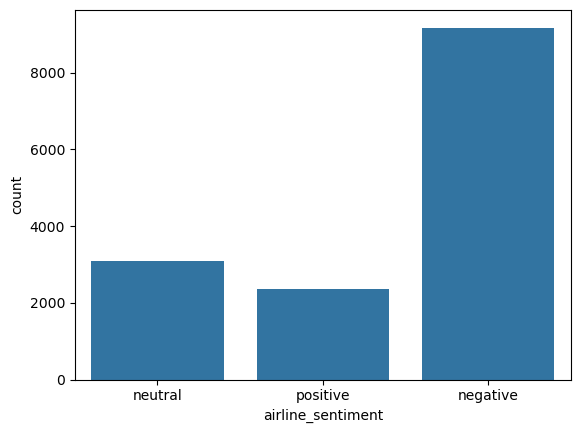

In [22]:
sns.countplot(dataset, x="airline_sentiment")

In [23]:
# le nombre de tweets negatifs
(dataset.airline_sentiment == "negative").sum()

9178

In [24]:
# le nombre de tweets neutres
(dataset.airline_sentiment == "neutral").sum()

3099

In [25]:
# le nombre de tweets positifs
(dataset.airline_sentiment == "positive").sum()

2363

In [26]:
# créer une colonne pour la taille de chaque tweet
dataset["length"] = dataset["text"].apply(len)

## Histogramme

<Axes: ylabel='Frequency'>

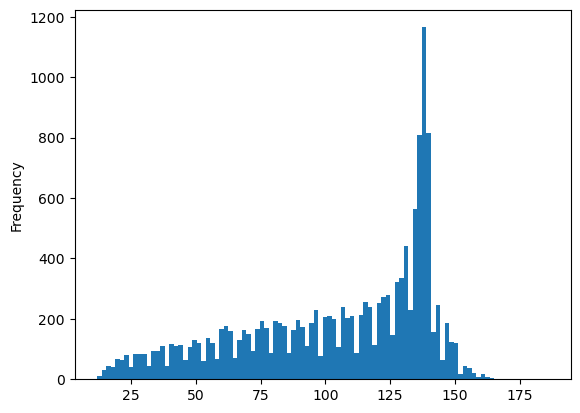

In [27]:
dataset["length"].plot(bins=100, kind="hist")

In [28]:
# on peut voir que la taille moyenne des tweets est environ 103 caractères
dataset.length.describe()

count    14640.000000
mean       103.822063
std         36.277339
min         12.000000
25%         77.000000
50%        114.000000
75%        136.000000
max        186.000000
Name: length, dtype: float64

In [29]:
# le tweet le plus long
dataset.length.max()

186

In [30]:
# afficher le tweet le plus long     # dataset["length"] == dataset.length.max()
dataset[dataset["length"] == 186]["text"].iloc[0]

"@USAirways Eyyyy! Cancelled Flightlations, Flight Booking Problemss, reFlight Booking Problemss, but y'all got me on the same flight out tonight (not tomorrow) &amp; the FC upgrade. Thx!"

In [31]:
# le tweet le plus court
dataset.length.min()

12

In [32]:
# afficher le tweet le plus court     # dataset["length"] == dataset.Length.min()
dataset[dataset["length"] == 12]["text"].iloc[0]

'@united done'

## Nuage des mots (Word Cloud)

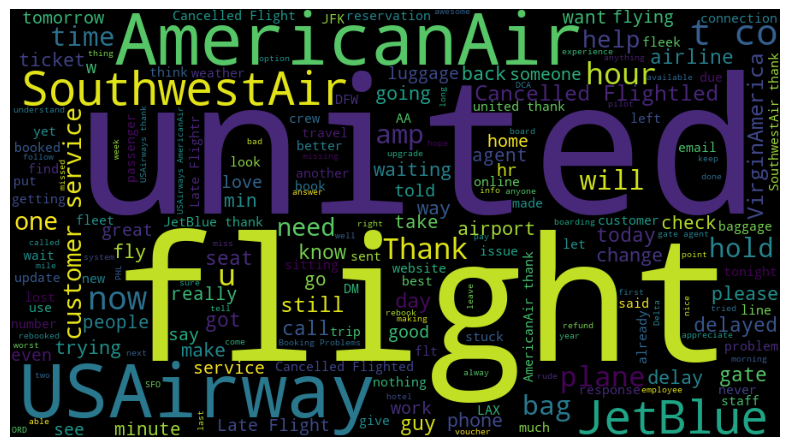

In [33]:
comment_words = ''
stopwords = set(STOPWORDS)

for val in dataset.text:
    val = str(val)
    tokens = val.split()
    comment_words = comment_words + " ".join(tokens)+ " "

wordcloud = WordCloud(width=900, height=500, background_color = 'black', 
                      stopwords = stopwords, min_font_size=10).generate(comment_words)

plt.figure(figsize = (8,8))
plt.imshow(wordcloud)
plt.axis('off')
plt.tight_layout()
plt.show()

# 5. Nettoyage des données

In [34]:
# garder juste les colonnes importante
dataset = dataset[["text", "airline_sentiment", "length"]]

In [35]:
# remplacer les valeurs de la variable "airline sentiment" par des entiers égaux à 0, 1 et 2
dataset["target"] = dataset["airline_sentiment"].replace( {"positive": 2, "neutral": 1, "negative": 0} )

In [36]:
dataset.head()

,text,airline_sentiment,length,target
0,@VirginAmerica What @dhepburn said.,neutral,35,1
1,@VirginAmerica plus you've added commercials t...,positive,72,2
2,@VirginAmerica I didn't today... Must mean I n...,neutral,71,1
3,@VirginAmerica it's really aggressive to blast...,negative,126,0
4,@VirginAmerica and it's a really big bad thing...,negative,55,0


## Nettoyage du text

In [37]:
# le nombre total des tweets dans le jeu de données
dataset.text.count()

14640

In [38]:
import re
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

corpus = []

# Initialisation en dehors de la boucle
ps = PorterStemmer()
all_stopwords = set(stopwords.words('english'))
all_stopwords.discard('not')  # On conserve "not" pour préserver la négation

# On a 14640 observations dans le dataset
for i in range(0, 14640):

    review = dataset['text'][i]

    # Suppression des mentions @
    review = re.sub(r'@\S+', '', review)

    # Suppression des URLs
    review = re.sub(r'http[^\s]+|www\S+', '', review)

    # Suppression des caractères non alphabétiques
    review = re.sub(r'[^a-zA-Z]', ' ', review)

    # Suppression des caractères spéciaux
    for c in "#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~":
        review = review.replace(c, "")

    # Mise en minuscules
    review = review.lower()

    # Tokenisation
    review = review.split()

    # Suppression des stopwords et stemming
    review = [ps.stem(word) for word in review
              if word not in all_stopwords]

    # Reconstitution du tweet
    review = ' '.join(review)

    # Ajout au corpus
    corpus.append(review)

In [39]:
print(len(corpus))

14640


In [40]:
print(corpus[:10])

['said', 'plu ad commerci experi tacki', 'today must mean need take anoth trip', 'realli aggress blast obnoxi entertain guest face amp littl recours', 'realli big bad thing', 'serious would pay flight seat play realli bad thing fli va', 'ye nearli everi time fli vx ear worm go away', 'realli miss prime opportun men without hat parodi', 'well', 'amaz arriv hour earli good']


## Tokenisation

* transformer le corpus de tweets nettoyés en une matrice numérique utilisable par un modèle de Machine Learning
* créer une matrice de fréquence des mots (bag of words)

In [41]:
from sklearn.feature_extraction.text import CountVectorizer

In [42]:
# création du modèle
cv = CountVectorizer(max_features=1500)

# tokenisation et création de la matrice
x = cv.fit_transform(corpus).toarray()

# variable cible
y = dataset['target'].values

In [43]:
len(x[0])

1500

In [44]:
x.shape

(14640, 1500)

In [45]:
y.shape

(14640,)

# 6. Train, Test, Split

In [46]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.20, random_state = 0)

In [47]:
x_train.shape

(11712, 1500)

In [48]:
x_test.shape

(2928, 1500)

In [49]:
y_train.shape

(11712,)

In [50]:
y_test.shape

(2928,)

# 7. Création du modèle

## 1) Arbre des décisions (RandomForestClassifier)

In [51]:
from sklearn.ensemble import RandomForestClassifier

classifier_rf = RandomForestClassifier()

classifier_rf.fit(x_train, y_train)

RandomForestClassifier()

In [52]:
# faire des prédictions
y_pred = classifier_rf.predict(x_test)

In [53]:
# valeurs de prédiction VS valeurs de test
print(np.concatenate((y_pred.reshape(len(y_pred),1), y_test.reshape(len(y_test),1)),1))

[[0 0]
 [1 0]
 [0 0]
 ...
 [0 0]
 [0 0]
 [0 0]]


In [54]:
# évaluer le modéle
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, precision_score, recall_score

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='weighted')
rec = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

rf_results = pd.DataFrame(
    [['Random Forest Classifier', acc, prec, rec, f1]],
    columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score']
)

rf_results

,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest Classifier,0.753757,0.742926,0.753757,0.746451


In [55]:
# accuracy
print(f"Accuracy: {acc*100:.2f}")

Accuracy: 75.38


In [56]:
# matrice de confusion
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[1647  150   73]
 [ 251  291   72]
 [ 112   63  269]]


## 2) Naive Bayes

In [57]:
from sklearn.naive_bayes import GaussianNB

classifier_nb = GaussianNB()

classifier_nb.fit(x_train, y_train)

GaussianNB()

In [58]:
# faire des péedictions
y_pred = classifier_nb.predict(x_test)

In [59]:
# valeurs de prédiction VS valeurs de test
print(np.concatenate((y_pred.reshape(len(y_pred),1), y_test.reshape(len(y_test),1)),1))

[[0 0]
 [0 0]
 [2 0]
 ...
 [2 0]
 [2 0]
 [0 0]]


In [60]:
# évaluer le modèle
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='weighted')
rec = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

nb_results = pd.DataFrame(
    [['Gaussian Naive Bayes', acc, prec, rec, f1]],
    columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score']
)

In [61]:
results = pd.concat([rf_results, nb_results], ignore_index=True)
results

,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest Classifier,0.753757,0.742926,0.753757,0.746451
1,Gaussian Naive Bayes,0.359290,0.678374,0.359290,0.376069


In [62]:
print(f"Accuracy: {acc*100:.2f}")

Accuracy: 35.93


In [63]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[ 509  338 1023]
 [  32  154  428]
 [  14   41  389]]


## 3) XGBoost Classifier

In [64]:
from xgboost import XGBClassifier

classifier_xgb = XGBClassifier(random_state=0)

classifier_xgb.fit(x_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [65]:
y_pred = classifier_xgb.predict(x_test)

In [66]:
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='weighted')
rec = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

xgb_results = pd.DataFrame([['XGBoost', acc, prec, rec, f1]],
               columns = ['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score'])

In [67]:
results = pd.concat([results, xgb_results], ignore_index=True)
results

,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest Classifier,0.753757,0.742926,0.753757,0.746451
1,Gaussian Naive Bayes,0.359290,0.678374,0.359290,0.376069
2,XGBoost,0.779372,0.769888,0.779372,0.771243


In [68]:
print(f"Accuracy: {acc*100}")

Accuracy: 77.93715846994536


In [69]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[1690  123   57]
 [ 257  315   42]
 [ 111   56  277]]


# 8. Tester le meilleur modèle sur de nouvelles observations

In [70]:
new_review = 'I love this flight so much'

new_review = re.sub('[^a-zA-Z]', ' ', new_review)
new_review = new_review.lower()
new_review = new_review.split()

ps = PorterStemmer()
all_stopwords = stopwords.words('english')
all_stopwords.remove('not')
new_review = [ps.stem(word) for word in new_review if not word in set(all_stopwords)]
new_review = ' '.join(new_review)

new_corpus = [new_review]
new_x_test = cv.transform(new_corpus).toarray()
new_y_pred = classifier_xgb.predict(new_x_test)

print(new_y_pred)

[2]


In [71]:
new_review = 'I hate this flight so much'

new_review = re.sub('[^a-zA-Z]', ' ', new_review)
new_review = new_review.lower()
new_review = new_review.split()

ps = PorterStemmer()
all_stopwords = stopwords.words('english')
all_stopwords.remove('not')
new_review = [ps.stem(word) for word in new_review if not word in set(all_stopwords)]
new_review = ' '.join(new_review)

new_corpus = [new_review]
new_x_test = cv.transform(new_corpus).toarray()
new_y_pred = classifier_xgb.predict(new_x_test)

print(new_y_pred)

[0]


In [72]:
# sauvegarder le meilleur modèle
import joblib
joblib.dump(classifier_xgb, "model.pkl")

['model.pkl']